# 06 – Kernel MSPC: choosing the kernel by monitoring performance

**Aim.** Treat the kernel choice as a process-monitoring problem, as in kernel multivariate statistical process
control (K-MSPC; Duma et al., 2026, and the `k-mspc` toolbox): a kPCA model learns **healthy operation only**,
and faults should appear as Hotelling T² or SPE values above control limits learned from healthy data. For
each of our kernels (linear, polynomial, Gaussian, Cauchy) the width / degree and the number of kPCs are
chosen by the monitoring loss ρ_b with grouped cross-validation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import kpca_tools as kt

FIG_DIR = "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

X, y = kt.load_meter_b()                       # raw data; variables and scaling are chosen per fold
G = kt.operating_point_groups(X, y, tol=0.1)
healthy = np.where(y == 1)[0]
print("X:", X.shape, " healthy samples:", len(healthy), " healthy groups:", len(np.unique(G[healthy])))

X: (92, 51)  healthy samples: 19  healthy groups: 8


## 1. Method

**Model of healthy operation.** In every cross-validation fold:
1. Only the **healthy training rows** are used to build the model (about 15 rows; faulty rows never).
2. Variables that are constant among these rows are dropped (the 17 variables that are fixed in the healthy
   state, notebook 01) and the rest are z-scored with the **healthy** mean and std. This is the MSPC
   convention: the model describes normal operation, and a fault is a deviation from it. (Notebooks 01–05
   used whole-data scaling because there the question was how all three classes are arranged.)
3. kPCA of the centred healthy kernel matrix $K_c = U \Lambda U^\top$, keeping $H$ kPCs; for Gaussian and
   Cauchy $\sigma$ = factor × median distance among the healthy training rows.

**Monitoring statistics** of a new sample $x$, with $k_c(x)$ its centred kernel vector against the training rows:

$$t_k(x) = \frac{k_c(x)^\top u_k}{\sqrt{\lambda_k}}, \qquad
T^2(x) = \sum_{k=1}^{H} \frac{t_k(x)^2}{\operatorname{var}(t_k)}, \qquad
\mathrm{SPE}(x) = k_c(x, x) - \sum_{k=1}^{H} t_k(x)^2 .$$

$T^2$ measures how unusual the sample is *inside* the kPC subspace (Hotelling's statistic, each kPC scaled to
unit variance); SPE is the squared distance of the sample to the subspace in feature space, i.e. the part the
healthy model cannot explain. For the linear kernel these are exactly the PCA $T^2$ and squared residual.

**Control limits: mean + 3·std**, as in the toolbox, but computed **out of sample**: every healthy training
group is left out once, the model is refitted on the other groups, and $T^2$ and SPE of the left-out rows are
pooled. The toolbox computes the limits from the training samples' own statistics, which works with hundreds
of healthy samples (Tennessee Eastman) but is far too tight with ~15 (section 4).

**Alarm and loss.** A sample raises an alarm if **$T^2$ or SPE** is above its limit. Performance per test fold:
false-alarm rate (FAR) on the healthy test rows, detection rates for gas injection and waxing, and the paper's
monitoring loss

$$\rho_b = 1 - \frac{\eta_n + \eta_f}{2},$$

$\eta_n$ = share of healthy test rows without alarm, $\eta_f$ = share of faulty test rows with alarm
(0 = perfect monitoring).

**Cross-validation and selection.** Same grouped CV as notebook 04 (operating-point groups,
`StratifiedGroupKFold`, 5 folds × 10 repeats). Grid: linear; polynomial d = 1–5; Gaussian and Cauchy
σ = median × 2^k, k = −4 … 4; and **H = 1–4** (upper bound from the Kaiser rule, section 2). Per kernel, among
all (setting, H) within one standard error of the lowest mean ρ_b, take the fewest kPCs, then the smoothest
setting. This is a grid-search version of the paper's kernel-parameter optimisation, which is sufficient
because each of our kernels has a single parameter.

**Differences from the toolbox.** Our kernels act on the whole variable vector (the toolbox sums
one-dimensional kernels per variable); $T^2$ is the standard Hotelling statistic; limits are out of sample.

## 2. Upper bound for the number of kPCs (Kaiser rule)
Eigenvalues of the correlation matrix of all healthy samples (variables that vary among them). The Kaiser rule
keeps components with λ > 1, i.e. those that explain more than one variable's worth of variance.

In [2]:
keep, mu, sd = kt.healthy_scaling(X, healthy)
Zh_all = (X[healthy][:, keep] - mu) / sd
lam = np.linalg.eigvalsh(np.corrcoef(Zh_all, rowvar=False))[::-1]
H_MAX = int((lam > 1).sum())
print("variables:", keep.sum(), "  first eigenvalues:", np.round(lam[:8], 2))
print(f"Kaiser rule: {H_MAX} components (explaining {100 * lam[:H_MAX].sum() / lam.sum():.1f} % of the variance) -> H = 1 ... {H_MAX}")

variables: 34   first eigenvalues: [28.2   1.93  1.34  1.02  0.67  0.4   0.2   0.1 ]
Kaiser rule: 4 components (explaining 95.6 % of the variance) -> H = 1 ... 4


## 3. Checks
An illustration split is used here and for the control charts (section 9): healthy groups at 2.4, 3.5, 5.3,
6.45 and 7.5 m/s for training; the healthy groups at 4.3, 5.9 and 7.0 m/s are held out.

In [3]:
h_groups = np.unique(G[healthy])                              # in file order = increasing flow
h_train = healthy[np.isin(G[healthy], h_groups[[0, 1, 3, 5, 7]])]
h_test = healthy[np.isin(G[healthy], h_groups[[2, 4, 6]])]
stream = np.r_[h_test, np.where(y == 2)[0], np.where(y == 3)[0]]   # held-out healthy, gas, waxing

# (a) linear kernel: T2 and SPE equal ordinary PCA's Hotelling T2 and squared residual
m = kt.kmspc_model(X, h_train, "linear", H_max=H_MAX)
Zh = (X[h_train][:, m["keep"]] - m["mu"]) / m["sd"]
Zs = (X[stream][:, m["keep"]] - m["mu"]) / m["sd"]
_, S, Vt = np.linalg.svd(Zh, full_matrices=False)
for H in range(1, H_MAX + 1):
    P = Vt[:H].T
    t = Zs @ P
    t2_pca = (t ** 2 / (S[:H] ** 2 / (len(Zh) - 1))).sum(axis=1)
    spe_pca = ((Zs - t @ P.T) ** 2).sum(axis=1)
    t2, spe = kt.kmspc_monitor(m, X, stream, H)
    assert np.allclose(t2, t2_pca) and np.allclose(spe, spe_pca, rtol=1e-6, atol=1e-8)

# (b) on the training rows, mean T2 = H (n - 1) / n (each kPC has unit variance with the n - 1 denominator)
for H in range(1, H_MAX + 1):
    t2, _ = kt.kmspc_monitor(m, X, h_train, H)
    assert np.isclose(t2.mean(), H * (len(h_train) - 1) / len(h_train))

# (c) grouped folds: no group on both sides, training always contains healthy rows,
#     every test fold contains healthy and faulty rows
for tr, te in kt.cv_splits(y, G):
    assert not set(G[tr]) & set(G[te])
    assert (y[tr] == 1).any() and (y[te] == 1).any() and (y[te] > 1).any()

print("All checks passed.")

All checks passed.


## 4. Training-sample limits vs. out-of-sample limits
False-alarm rate and ρ_b (alarm = T² or SPE) with the toolbox's training-sample limits and with our
out-of-sample limits, for three settings and H = 1–4.

In [4]:
print(f"{'setting':<22}{'limits':>8} |" + "".join(f"{'FAR H=' + str(H):>9}" for H in range(1, H_MAX + 1))
      + " |" + "".join(f"{'rho H=' + str(H):>9}" for H in range(1, H_MAX + 1)))
for label, kind, kw in [("Linear", "linear", {}), ("Gaussian sigma x4", "rbf", dict(factor=4.0)),
                        ("Gaussian sigma x1", "rbf", dict(factor=1.0))]:
    for lim in ("train", "oos"):
        r = kt.cv_monitoring(X, y, G, kind, H_max=H_MAX, limits=lim, **kw)["either"]
        print(f"{label:<22}{lim:>8} |" + "".join(f"{v:9.2f}" for v in r["FAR"].mean(0))
              + " |" + "".join(f"{v:9.3f}" for v in r["rho"].mean(0)))

setting                 limits |  FAR H=1  FAR H=2  FAR H=3  FAR H=4 |  rho H=1  rho H=2  rho H=3  rho H=4


Linear                   train |     0.26     0.47     0.54     0.70 |    0.128    0.237    0.270    0.350


Linear                     oos |     0.04     0.04     0.04     0.06 |    0.020    0.020    0.020    0.030


Gaussian sigma x4        train |     0.26     0.51     0.57     0.70 |    0.128    0.253    0.287    0.350


Gaussian sigma x4          oos |     0.00     0.00     0.02     0.04 |    0.000    0.000    0.010    0.020


Gaussian sigma x1        train |     0.22     0.54     0.65     0.73 |    0.112    0.270    0.327    0.367


Gaussian sigma x1          oos |     0.20     0.00     0.20     0.22 |    0.210    0.110    0.210    0.220


## 5. Cross-validation over the grid (out-of-sample limits)

In [5]:
factors = 2.0 ** np.arange(-4, 5)
GRID = {   # kernel: list of (label, value, kind, arguments), from smoothest to least smooth
    "Linear":   [("–", None, "linear", {})],
    "Poly":     [(f"d={d}", d, "poly", dict(degree=d)) for d in range(1, 6)],
    "Gaussian": [(f"{f:g}", f, "rbf", dict(factor=f)) for f in factors[::-1]],
    "Cauchy":   [(f"{f:g}", f, "cauchy", dict(factor=f)) for f in factors[::-1]],
}
mon = {}
for kernel, settings in GRID.items():
    for label, value, kind, kw in settings:
        mon[(kernel, label)] = dict(value=value, kind=kind, kw=kw,
                                    res=kt.cv_monitoring(X, y, G, kind, H_max=H_MAX, **kw))
print(f"Evaluated {len(mon)} settings x H = 1..{H_MAX} x 50 grouped train/test splits.")

def mean_se(a):
    return a.mean(axis=0), a.std(axis=0, ddof=1) / np.sqrt(len(a))

Evaluated 24 settings x H = 1..4 x 50 grouped train/test splits.


## 6. Choosing the setting and the number of kPCs (alarm = T² or SPE)

In [6]:
chosen = {}
for kernel, settings in GRID.items():
    cand = []                                   # preference order: fewest kPCs first, then smoothest setting
    for H in range(1, H_MAX + 1):
        for label, *_ in settings:
            m_, se_ = mean_se(mon[(kernel, label)]["res"]["either"]["rho"])
            cand.append((label, H, m_[H - 1], se_[H - 1]))
    best = min(cand, key=lambda c: c[2])
    label, H, rho, _ = next(c for c in cand if c[2] <= best[2] + best[3])
    chosen[kernel] = (label, H)
    print(f"{kernel:<9} lowest rho_b {best[2]:.3f} (SE {best[3]:.3f}) at {best[0]}, H={best[1]}"
          f"  ->  chosen {label}, H={H} (rho_b {rho:.3f})")

Linear    lowest rho_b 0.020 (SE 0.011) at –, H=1  ->  chosen –, H=1 (rho_b 0.020)
Poly      lowest rho_b 0.000 (SE 0.000) at d=3, H=1  ->  chosen d=3, H=1 (rho_b 0.000)
Gaussian  lowest rho_b 0.000 (SE 0.000) at 16, H=1  ->  chosen 16, H=1 (rho_b 0.000)
Cauchy    lowest rho_b 0.000 (SE 0.000) at 16, H=1  ->  chosen 16, H=1 (rho_b 0.000)


## 7. Monitoring performance against the setting
Top: balanced rate of correct monitoring, 1 − ρ_b (alarm = T² or SPE), for H = 1–4. Bottom: at the chosen H,
the same rate for T² alone, SPE alone and the combined alarm. The dashed line is the linear kernel at its
chosen H; the ring marks the chosen setting.

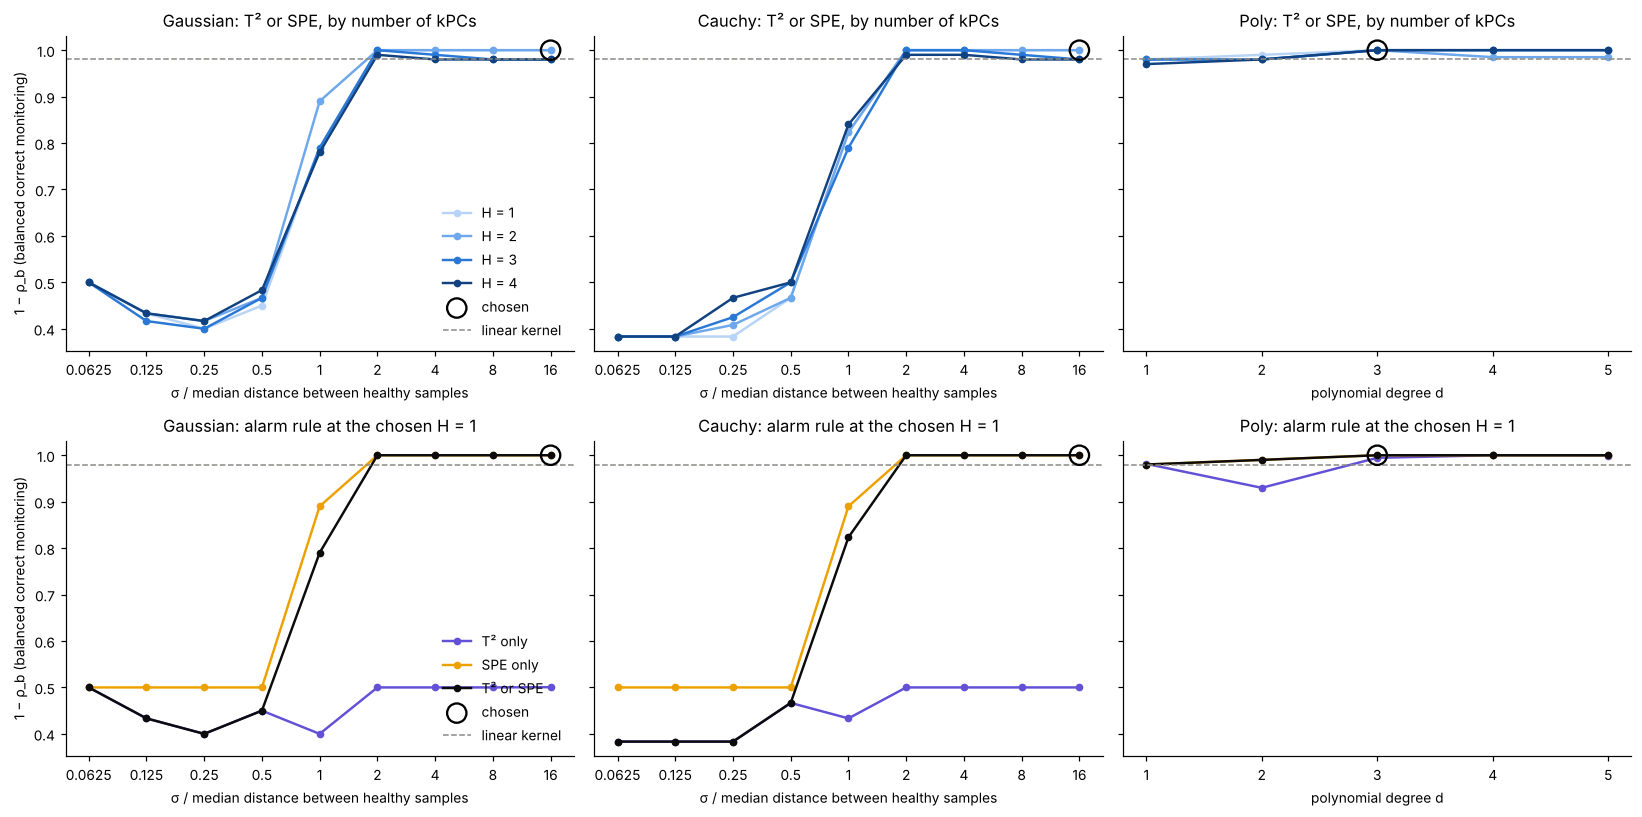

In [7]:
H_COLORS = {1: "#b7d3f6", 2: "#6da7ec", 3: "#2a78d6", 4: "#104281"}   # one hue, darker = more kPCs
STAT_STYLE = {"T2": ("#6250d6", "-", "T² only"), "SPE": ("#eda100", "-", "SPE only"),
              "either": ("#0b0b0b", "-", "T² or SPE")}
lab_lin, H_lin = chosen["Linear"]
lin_rate = 1 - mon[("Linear", lab_lin)]["res"]["either"]["rho"].mean(0)[H_lin - 1]

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey="row")
for col, kernel in enumerate(["Gaussian", "Cauchy", "Poly"]):
    settings = sorted(GRID[kernel], key=lambda s: s[1])
    x = np.array([s[1] for s in settings], dtype=float)
    lab_c, H_c = chosen[kernel]
    for H in range(1, H_MAX + 1):
        r = np.array([1 - mon[(kernel, s[0])]["res"]["either"]["rho"].mean(0)[H - 1] for s in settings])
        axes[0, col].plot(x, r, marker="o", ms=4, lw=1.6, color=H_COLORS[H], label=f"H = {H}")
    for stat, (c, ls, name) in STAT_STYLE.items():
        r = np.array([1 - mon[(kernel, s[0])]["res"][stat]["rho"].mean(0)[H_c - 1] for s in settings])
        axes[1, col].plot(x, r, marker="o", ms=4, lw=1.6, color=c, ls=ls, label=name)
    v_c = mon[(kernel, lab_c)]["value"]
    r_c = 1 - mon[(kernel, lab_c)]["res"]["either"]["rho"].mean(0)[H_c - 1]
    for row in range(2):
        ax = axes[row, col]
        ax.scatter([v_c], [r_c], s=160, facecolor="none", edgecolor="k", lw=1.5, zorder=5,
                   label="chosen" if col == 0 else None)
        ax.axhline(lin_rate, color="#8b8a86", ls="--", lw=1, label="linear kernel" if col == 0 else None)
        if kernel == "Poly":
            ax.set_xticks(x)
            ax.set_xlabel("polynomial degree d")
        else:
            ax.set_xscale("log", base=2)
            ax.set_xticks(x, [f"{f:g}" for f in x])
            ax.set_xlabel("σ / median distance between healthy samples")
    axes[0, col].set_title(f"{kernel}: T² or SPE, by number of kPCs")
    axes[1, col].set_title(f"{kernel}: alarm rule at the chosen H = {H_c}")
axes[0, 0].set_ylabel("1 − ρ_b (balanced correct monitoring)")
axes[1, 0].set_ylabel("1 − ρ_b (balanced correct monitoring)")
axes[0, 0].legend(frameon=False, loc="lower right")
axes[1, 0].legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m7_rho_curves.png")
plt.show()

## 8. Results for the chosen settings
Mean over the 50 grouped train/test splits (± standard error of ρ_b).

In [8]:
def row(kernel, label, H, stat):
    r = mon[(kernel, label)]["res"][stat]
    m_, se_ = mean_se(r["rho"])
    return (f"{r['FAR'].mean(0)[H - 1]:6.2f}{r['gas'].mean(0)[H - 1]:7.2f}{r['waxing'].mean(0)[H - 1]:8.2f}"
            f"{m_[H - 1]:9.3f} ± {se_[H - 1]:.3f}")

print(f"{'kernel':<9}{'setting':>8}{'H':>3} {'alarm':<7}{'FAR':>6}{'gas':>7}{'waxing':>8}{'rho_b':>9}")
for kernel, (label, H) in chosen.items():
    for stat in ("T2", "SPE", "either"):
        print(f"{kernel:<9}{label:>8}{H:>3} {stat:<7}" + row(kernel, label, H, stat))
    print()

print("rho_b (T2 or SPE) against H at the chosen setting:")
for kernel, (label, H) in chosen.items():
    m_, se_ = mean_se(mon[(kernel, label)]["res"]["either"]["rho"])
    print(f"  {kernel:<9}{label:>6}  " + "  ".join(f"H={h}: {m_[h - 1]:.3f}" for h in range(1, H_MAX + 1)))

print("\nFor comparison, sigma = median distance:")
for kernel in ("Gaussian", "Cauchy"):
    H = chosen[kernel][1]
    for stat in ("T2", "SPE", "either"):
        print(f"  {kernel:<9} x1  H={H} {stat:<7}" + row(kernel, "1", H, stat))

kernel    setting  H alarm     FAR    gas  waxing    rho_b
Linear          –  1 T2       0.00   0.90    1.00    0.019 ± 0.004
Linear          –  1 SPE      0.04   1.00    1.00    0.020 ± 0.011
Linear          –  1 either   0.04   1.00    1.00    0.020 ± 0.011

Poly          d=3  1 T2       0.00   0.97    1.00    0.006 ± 0.002
Poly          d=3  1 SPE      0.00   1.00    1.00    0.000 ± 0.000
Poly          d=3  1 either   0.00   1.00    1.00    0.000 ± 0.000

Gaussian       16  1 T2       0.00   0.00    0.00    0.499 ± 0.001
Gaussian       16  1 SPE      0.00   1.00    1.00    0.000 ± 0.000
Gaussian       16  1 either   0.00   1.00    1.00    0.000 ± 0.000

Cauchy         16  1 T2       0.00   0.00    0.00    0.500 ± 0.000
Cauchy         16  1 SPE      0.00   1.00    1.00    0.000 ± 0.000
Cauchy         16  1 either   0.00   1.00    1.00    0.000 ± 0.000

rho_b (T2 or SPE) against H at the chosen setting:
  Linear        –  H=1: 0.020  H=2: 0.020  H=3: 0.020  H=4: 0.030
  Poly        d=

## 9. Control charts (illustration split)
One model per row, trained on the five training healthy groups, with out-of-sample limits from those groups.
The test stream is: the three held-out healthy groups, then all gas-injection samples, then all waxing samples.
Filled markers = alarm (above the dashed limit), open markers = no alarm. The quantitative results are those of
section 8; this split only illustrates what the charts look like.

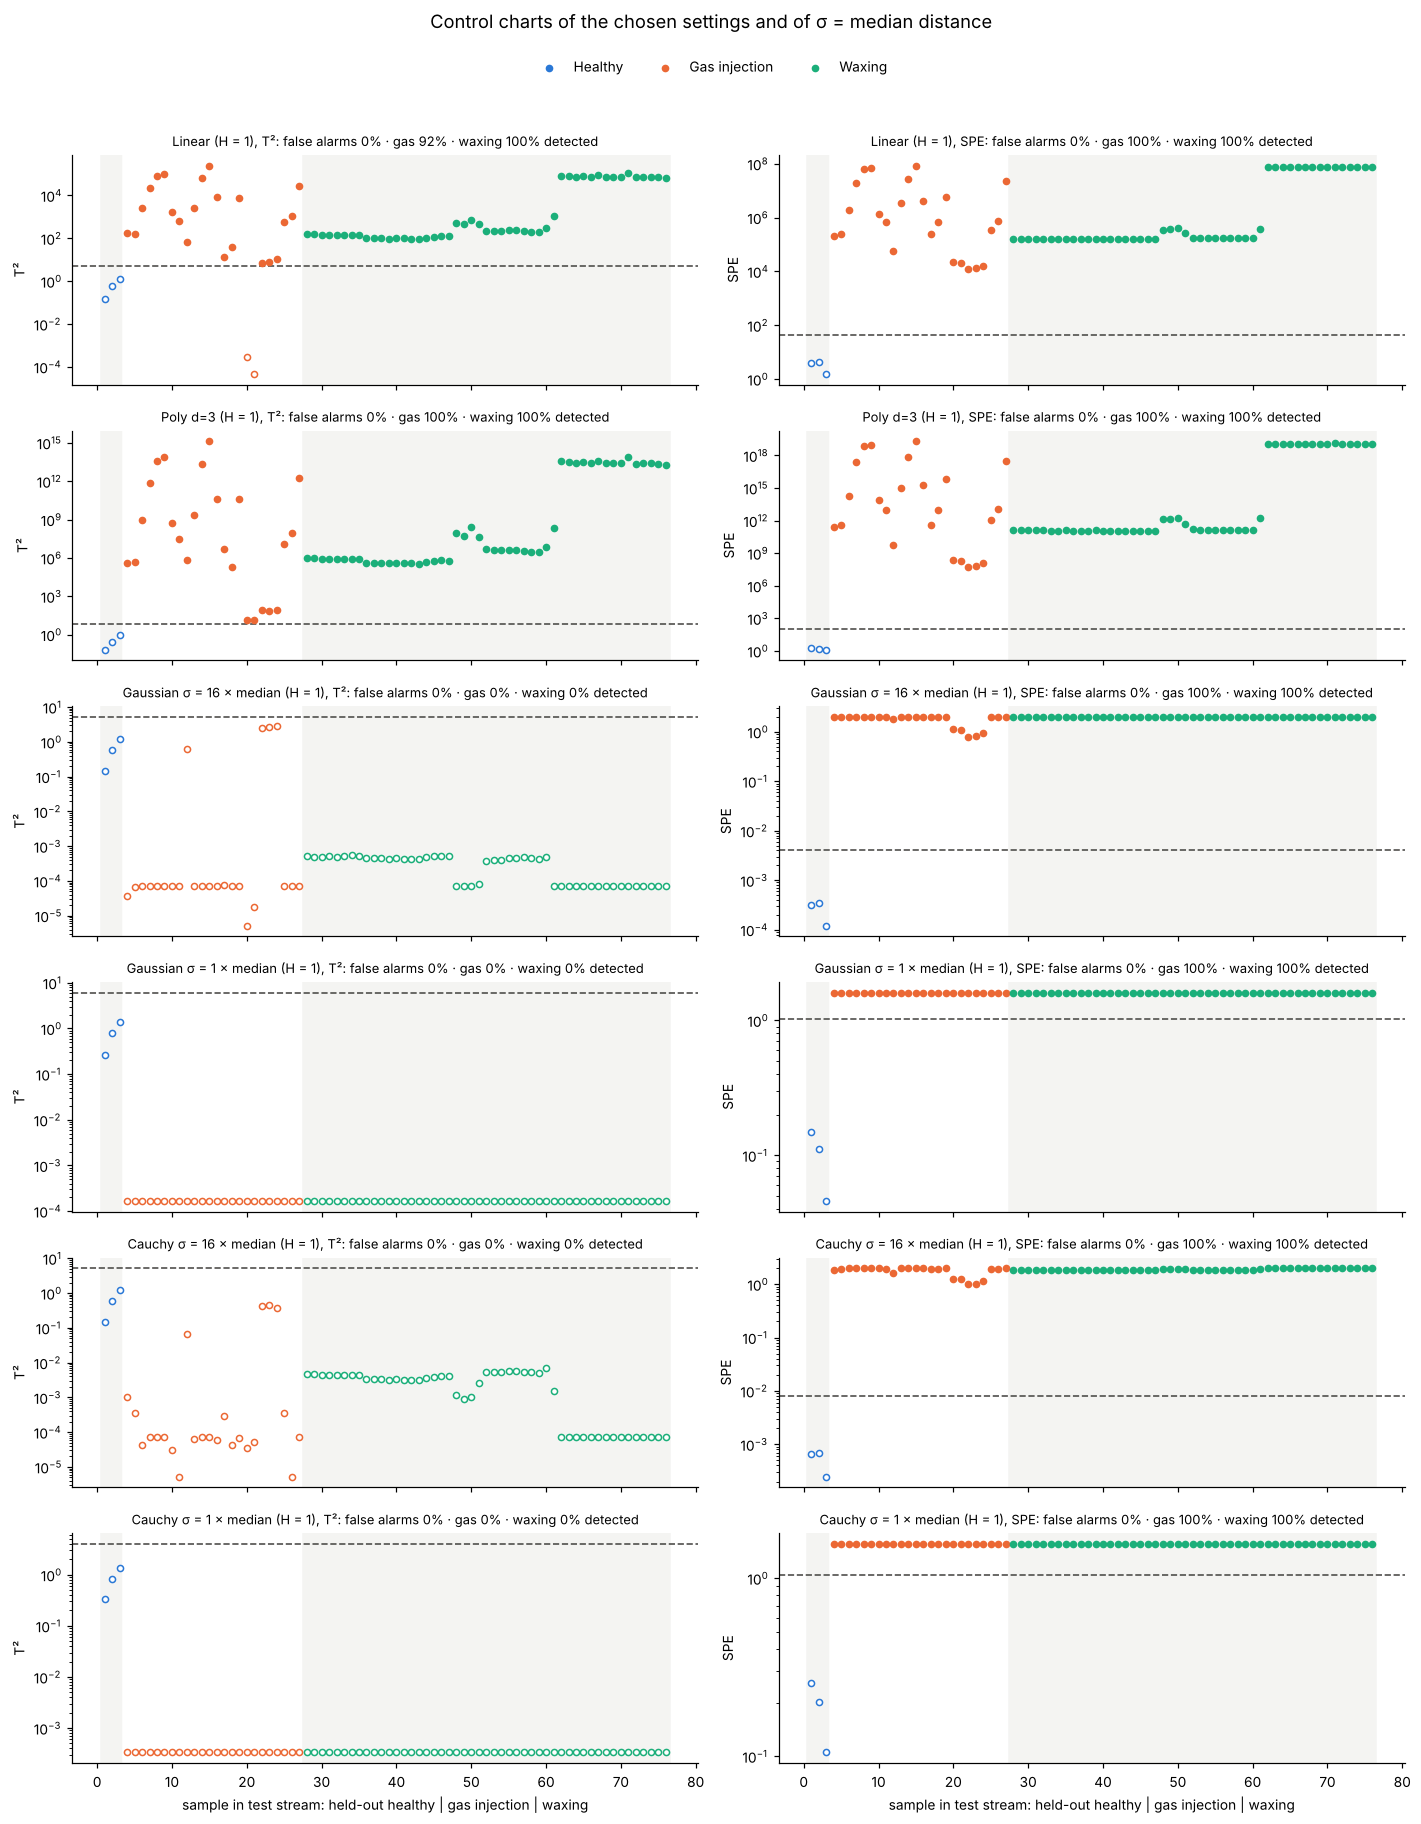

In [9]:
seg = y[stream]
idx = np.arange(1, len(stream) + 1)
bounds = [0.5, len(h_test) + 0.5, len(h_test) + (y == 2).sum() + 0.5, len(stream) + 0.5]

def chart_rows(rows, fname, title):
    fig, axes = plt.subplots(len(rows), 2, figsize=(13, 2.6 * len(rows) + 0.6), sharex=True, squeeze=False)
    for r, (name, kind, kw, H) in enumerate(rows):
        model = kt.kmspc_model(X, h_train, kind, H_max=H_MAX, **kw)
        lims = kt.oos_limits(X, h_train, G, kind, H_max=H_MAX, **kw)[H]
        stats = kt.kmspc_monitor(model, X, stream, H)
        for k, (val, lim, sname) in enumerate(zip(stats, lims, ("T²", "SPE"))):
            ax = axes[r, k]
            floor = max(val[val > 0].min() / 3, lim / 1e6) if (val > 0).any() else lim / 1e6
            val = np.maximum(val, floor)
            for b in range(3):
                ax.axvspan(bounds[b], bounds[b + 1], color=["#f4f4f2", "#ffffff", "#f4f4f2"][b], zorder=0)
            for c in kt.CLASS_NAMES:
                mk = seg == c
                above = val > lim
                ax.scatter(idx[mk & above], val[mk & above], s=16, color=kt.CLASS_COLORS[c], zorder=3,
                           label=kt.CLASS_NAMES[c] if (r == 0 and k == 0) else None)
                ax.scatter(idx[mk & ~above], val[mk & ~above], s=16, facecolor="white",
                           edgecolor=kt.CLASS_COLORS[c], lw=1.0, zorder=3)
            ax.axhline(lim, color="#52514e", ls="--", lw=1.1)
            ax.set_yscale("log")
            ax.set_ylabel(sname)
            rates = kt.monitoring_rates(val > lim, seg)
            ax.set_title(f"{name}, {sname}: false alarms {rates['FAR']:.0%} · gas {rates['gas']:.0%} · "
                         f"waxing {rates['waxing']:.0%} detected", fontsize=8.5)
    for ax in axes[-1]:
        ax.set_xlabel("sample in test stream: held-out healthy | gas injection | waxing")
    fig.legend(loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title, y=1.02, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(f"{FIG_DIR}/{fname}", bbox_inches="tight")
    plt.show()

def setting(kernel, label=None):
    label, H = (label or chosen[kernel][0]), chosen[kernel][1]
    kind, kw = mon[(kernel, label)]["kind"], mon[(kernel, label)]["kw"]
    shown = {"Linear": "Linear", "Poly": f"Poly {label}"}.get(kernel, f"{kernel} σ = {label} × median")
    return (f"{shown} (H = {H})", kind, kw, H)

FULL_ROWS = [setting("Linear"), setting("Poly"), setting("Gaussian"), setting("Gaussian", "1"),
             setting("Cauchy"), setting("Cauchy", "1")]
chart_rows(FULL_ROWS, "m7_control_charts.png", "Control charts of the chosen settings and of σ = median distance")

**Reduced version for the report** (three rows: the linear kernel, the chosen Gaussian kernel, and the
Gaussian kernel at σ = median distance, which shows the T² collapse).

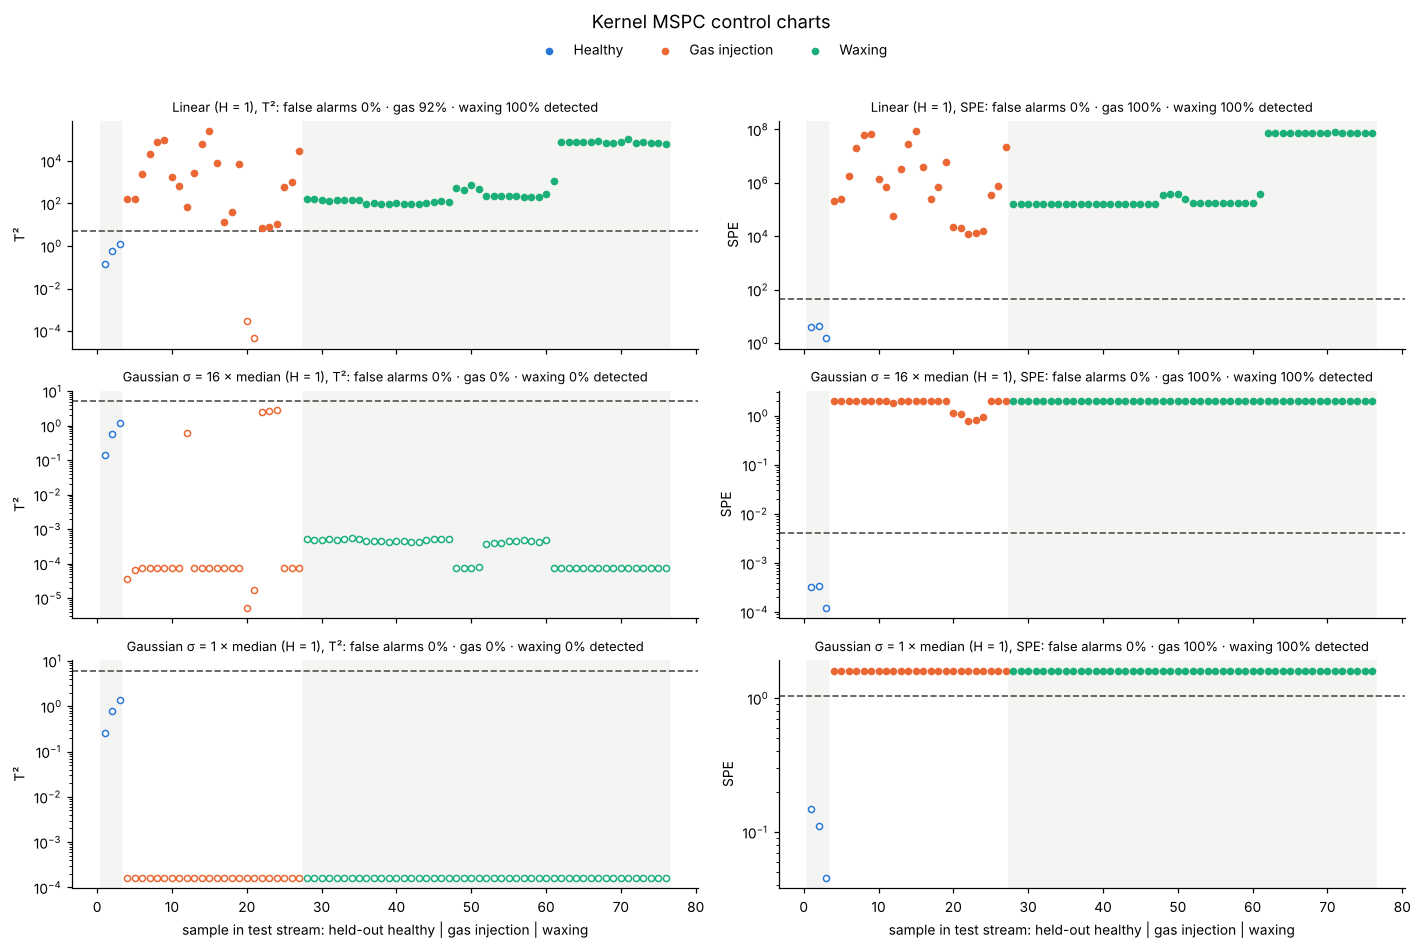

In [10]:
chart_rows([setting("Linear"), setting("Gaussian"), setting("Gaussian", "1")],
           "m7_control_charts_report.png", "Kernel MSPC control charts")

## 10. T² against SPE
The same illustration split, both statistics at once (log–log, dashed lines = limits). Samples in the lower-left
rectangle raise no alarm. Where gas injection and waxing fall in this plane shows whether the monitoring
statistics also tell the two faults apart, not only detect them.

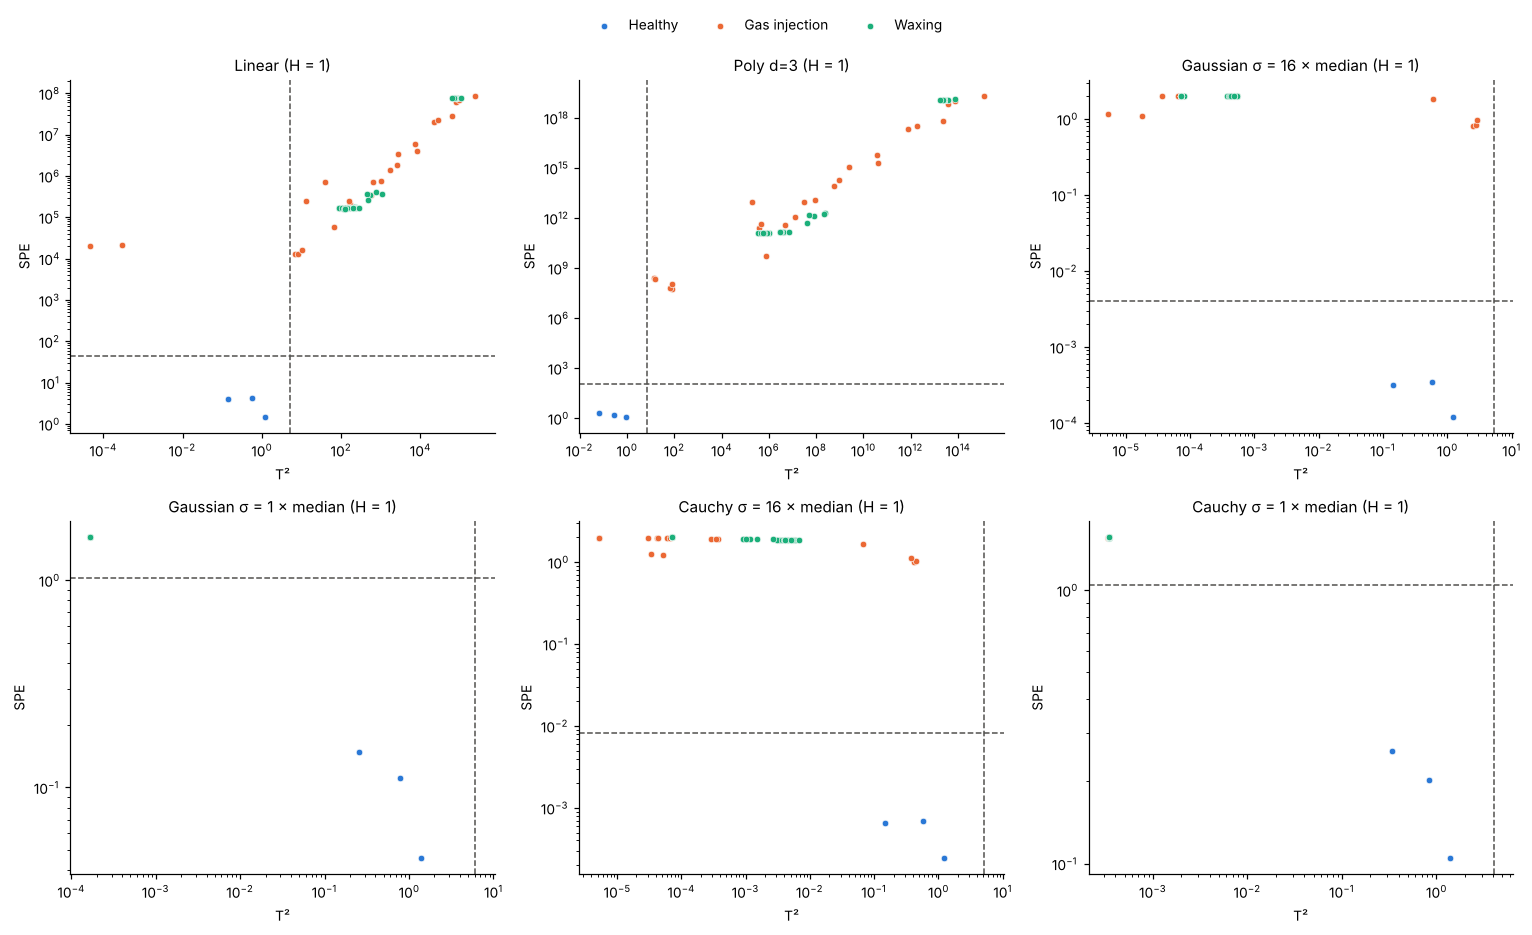

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, (name, kind, kw, H) in zip(axes.flat, FULL_ROWS):
    model = kt.kmspc_model(X, h_train, kind, H_max=H_MAX, **kw)
    l2, lq = kt.oos_limits(X, h_train, G, kind, H_max=H_MAX, **kw)[H]
    t2, spe = kt.kmspc_monitor(model, X, stream, H)
    t2, spe = np.maximum(t2, l2 / 1e6), np.maximum(spe, lq / 1e6)
    for c in kt.CLASS_NAMES:
        mk = seg == c
        ax.scatter(t2[mk], spe[mk], s=18, color=kt.CLASS_COLORS[c], edgecolor=kt.SURFACE, linewidth=0.4,
                   label=kt.CLASS_NAMES[c])
    ax.axvline(l2, color="#52514e", ls="--", lw=1)
    ax.axhline(lq, color="#52514e", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("T²"); ax.set_ylabel("SPE")
    ax.set_title(name, fontsize=10)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(f"{FIG_DIR}/m7_t2_vs_spe.png")
plt.show()

## 11. Interpretation

**Checks.** With the linear kernel, our T² and SPE are identical to ordinary PCA's Hotelling T² and squared
residual; the training T² has the expected mean H(n − 1)/n; no operating-point group is ever on both sides of a
split, and only healthy training rows are used for the model and its limits.

**Control limits (section 4).** With the toolbox's training-sample limits, 26–73 % of the held-out healthy
samples raise an alarm, rising with the number of kPCs: a model fitted to ~15 samples explains its own
samples much better than new ones, so the limits are far too tight. Out-of-sample limits bring the false-alarm
rate of the linear and wide Gaussian models down to 0–6 %. All results below use out-of-sample limits.

**Monitoring is easy for good kernels.** The faults of Meter B are gross deviations from healthy operation
(thousands of healthy standard deviations in some variables). The chosen settings detect **100 % of
gas-injection and waxing samples** (alarm = T² or SPE):

| Kernel (chosen) | H | False alarms | Gas detected | Waxing detected | ρ_b |
|---|---|---|---|---|---|
| Linear | 1 | 4 % | 100 % | 100 % | 0.020 |
| Polynomial d = 3 | 1 | 0 % | 100 % | 100 % | 0.000 |
| Gaussian σ = 16 × median | 1 | 0 % | 100 % | 100 % | 0.000 |
| Cauchy σ = 16 × median | 1 | 0 % | 100 % | 100 % | 0.000 |

With one kPC, Gaussian and Cauchy reach ρ_b = 0 for every σ ≥ 2 × median, and the polynomial kernel for
d = 3–5. The linear
kernel's only false alarms are the two healthy samples at 2.4 m/s, the lowest flow rate, which the model has to
extrapolate to when that group is held out (3 of 10 repeats). With 19 healthy samples in 8 groups the
false-alarm rates are coarse, so linear (4 %) and the best kernels (0 %) differ by very little.

**The kernel decides *which* statistic detects the faults (sections 7–10).**
- **Linear and polynomial:** T² and SPE both detect almost all faults; the faults spread over many orders of
  magnitude in both statistics.
- **Gaussian and Cauchy: T² collapse.** T² detects **no** faults, at any width. A fault is so far from every
  healthy sample that all its kernel values are ≈ 0; its centred kernel vector is then the same for every
  fault, so all faults project to the same point inside the healthy region of the kPCs. Detection comes
  entirely from SPE, which is large because nothing about the fault is explained by the healthy model. The
  combined alarm (T² or SPE) is therefore essential for these kernels.
- **Narrow width fails (σ ≤ median).** For narrow kernels a healthy operating point that was not in training
  also looks "completely unfamiliar", so its SPE reaches the same ceiling as a fault: the held-out 3.5 m/s
  healthy group always raises an alarm, and in folds where such a group sets the limits, faults are missed
  (detection 78 %, ρ_b ≈ 0.2). A narrow kernel cannot tell a new healthy operating point from a fault.
- **Number of kPCs.** One kPC is enough everywhere; more kPCs never improve ρ_b and slightly increase false
  alarms (e.g. linear H = 4: 6 %).

**Detection, not identification (section 10).** In the T²–SPE plane gas injection and waxing overlap (linear,
polynomial) or collapse onto the same point (Gaussian, Cauchy). The monitoring statistics answer "is the meter
faulty?", not "which fault?". Telling gas injection from waxing is done by the kPC scores and biplots of
notebook 05.

## Summary – carried into the report
- **Kernel choice by monitoring (TA's suggestion):** wide Gaussian or Cauchy kernels (σ ≥ 2 × median of the
  healthy distances) and polynomial kernels of degree 3–5 give perfect monitoring in grouped CV (no false
  alarms, all faults detected) with a single kPC; linear PCA is almost as good (4 % false alarms).
- **How the kernel was selected:** grid search over σ / degree and H = 1–4 (Kaiser bound) on the paper's loss
  ρ_b, alarm = T² or SPE, grouped CV, out-of-sample limits, smallest H and smoothest setting within one
  standard error.
- **Lessons:** with local kernels the faults are detected by SPE, never by T²; widths at or below the median
  distance confuse new healthy operating points with faults; training-sample control limits are unusable with
  so few healthy samples.
